In [1]:
import os
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

In [2]:
import os
from tensorflow.keras.preprocessing.image import  ImageDataGenerator
from keras.layers import Dense,Flatten,GlobalAveragePooling2D,Input,Conv2D,MaxPooling2D,Dropout
from keras.models import Model,load_model,Sequential
from keras.applications.xception import  Xception
from keras.applications.vgg16 import VGG16
from keras.applications.vgg19 import VGG19
from keras.applications.resnet50 import  ResNet50
from keras.applications.inception_v3 import InceptionV3
from keras.applications.inception_resnet_v2 import InceptionResNetV2
from keras.applications.mobilenet import MobileNet
import keras.callbacks as kcallbacks
import keras
from keras.preprocessing.image import load_img,img_to_array
import math
import random
from keras.utils import plot_model
import matplotlib.pyplot as plt
import sklearn.metrics as metrics
import numpy as np
from PIL import Image
import sklearn.metrics as metrics
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
from sklearn.metrics import classification_report
from sklearn.utils.class_weight import compute_class_weight

2026-05-30 14:40:51.600319: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [4]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

TARGET_SIZE = (224, 224)
INPUT_SIZE = (224, 224, 3)
BATCHSIZE = 128

# 1. Normalization (Remove validation_split here)
# It is best practice to use separate generator instances, 
# even if both just rescale, to prevent future accidental leakage if you add augmentation later.
train_datagen = ImageDataGenerator(rescale=1./255)
val_test_datagen = ImageDataGenerator(rescale=1./255)

# Update these classes based on your actual CICIDS2017 labels
wanted_classes = ['DoS', 'Fuzzy', 'RPM', 'Advanced', 'Patator', 'BENIGN']

# 2. Train Generator (Points directly to the 'train' folder)
train_generator = train_datagen.flow_from_directory(
    directory='../Images/train/', # Update this to your actual train images path
    classes=wanted_classes, 
    target_size=TARGET_SIZE,
    batch_size=BATCHSIZE,
    class_mode='categorical',
    shuffle=True, # Shuffle training data
    seed=42
)

# 3. Validation Generator (Points directly to the 'val' folder)
validation_generator = val_test_datagen.flow_from_directory(
    directory='../Images/val/', # Update this to your actual val images path
    classes=wanted_classes, 
    target_size=TARGET_SIZE,
    batch_size=BATCHSIZE,
    class_mode='categorical',
    shuffle=False, # Do not shuffle validation data
    seed=42
)


Found 1707118 images belonging to 6 classes.
Found 565575 images belonging to 6 classes.


In [5]:
class LossHistory(keras.callbacks.Callback):
    def on_train_begin(self, logs={}):
        self.losses = {'batch':[], 'epoch':[]}
        self.accuracy = {'batch':[], 'epoch':[]}
        self.val_loss = {'batch':[], 'epoch':[]}
        self.val_accuracy = {'batch':[], 'epoch':[]}
    def on_batch_end(self, batch, logs={}):
        self.losses['batch'].append(logs.get('loss'))
        self.accuracy['batch'].append(logs.get('acc'))
        self.val_loss['batch'].append(logs.get('val_loss'))
        self.val_accuracy['batch'].append(logs.get('val_accuracy'))
    def on_epoch_end(self, batch, logs={}):
        self.losses['epoch'].append(logs.get('loss'))
        self.accuracy['epoch'].append(logs.get('acc'))
        self.val_loss['epoch'].append(logs.get('val_loss'))
        self.val_accuracy['epoch'].append(logs.get('val_accuracy'))
    def loss_plot(self, loss_type):
        iters = range(len(self.losses[loss_type]))
        plt.figure()
        plt.plot(iters, self.losses[loss_type], 'g', label='train loss')
        if loss_type == 'epoch':
            # acc
            plt.plot(iters, self.accuracy[loss_type], 'r', label='train acc')
            # loss
            plt.plot(iters, self.losses[loss_type], 'g', label='train loss')
            # val_acc
            plt.plot(iters, self.val_accuracy[loss_type], 'b', label='val_accuracy')
            # val_loss
            plt.plot(iters, self.val_loss[loss_type], 'k', label='val loss')
        plt.grid(True)
        plt.xlabel(loss_type)
        plt.ylabel('acc-loss')
        plt.legend(loc="upper right")
        plt.show()
history_this= LossHistory()

In [11]:
def xception(num_class, epochs, savepath='./xception_smot.keras', history=history_this, input_shape=INPUT_SIZE):
    base_model = keras.applications.Xception(include_top=False, weights='imagenet', input_shape=input_shape)
    for layer in base_model.layers[:100]:
        layer.trainable = False
    for layer in base_model.layers[100:]:
        layer.trainable = True

    x = GlobalAveragePooling2D()(base_model.output)
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.5)(x)
    output = Dense(num_class, activation='softmax')(x)
    model = Model(base_model.input, output, name='xception')

    opt = keras.optimizers.Adam(learning_rate=1e-5)
    model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])

    y_train = train_generator.classes
    class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
    class_weight_dict = dict(enumerate(class_weights))

    callbacks = [
        kcallbacks.EarlyStopping(monitor='val_accuracy', patience=2, mode='max', verbose=1),
        kcallbacks.ModelCheckpoint(filepath=savepath, monitor='val_accuracy', save_best_only=True)
    ]

    model.fit(train_generator,
              validation_data=validation_generator,
              epochs=epochs,
              steps_per_epoch=len(train_generator),
              validation_steps=len(validation_generator),
              callbacks=callbacks + [history],
              class_weight=class_weight_dict)

    y_pred = model.predict(validation_generator)
    y_true = validation_generator.classes
    y_pred_classes = np.argmax(y_pred, axis=1)
    class_names = list(validation_generator.class_indices.keys())
    print(classification_report(y_true, y_pred_classes, target_names=class_names))


/home/minyar/tf-venv/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
 3338/13337 ━━━━━━━━━━━━━━━━━━━━ 1:06:58 402ms/step - accuracy: 0.7946 - loss: 0.4340

2026-05-11 19:43:26.932601: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6471', 8 bytes spill stores, 8 bytes spill loads

2026-05-11 19:43:27.284935: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6613', 4 bytes spill stores, 4 bytes spill loads

2026-05-11 19:43:27.598271: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_8675', 132 bytes spill stores, 132 bytes spill loads

2026-05-11 19:43:27.889439: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6112', 10232 bytes spill stores, 10436 bytes spill loads



13337/13337 ━━━━━━━━━━━━━━━━━━━━ 6715s 502ms/step - accuracy: 0.8650 - loss: 0.2245 - val_accuracy: 0.9219 - val_loss: 0.2967
Epoch 2/10
13337/13337 ━━━━━━━━━━━━━━━━━━━━ 6675s 500ms/step - accuracy: 0.9307 - loss: 0.0685 - val_accuracy: 0.9119 - val_loss: 0.3680
Epoch 3/10
13337/13337 ━━━━━━━━━━━━━━━━━━━━ 6687s 501ms/step - accuracy: 0.9479 - loss: 0.0564 - val_accuracy: 0.9511 - val_loss: 0.2125
Epoch 4/10
13337/13337 ━━━━━━━━━━━━━━━━━━━━ 6768s 507ms/step - accuracy: 0.9554 - loss: 0.0507 - val_accuracy: 0.9208 - val_loss: 0.2841
Epoch 5/10
13337/13337 ━━━━━━━━━━━━━━━━━━━━ 6802s 510ms/step - accuracy: 0.9568 - loss: 0.0484 - val_accuracy: 0.9452 - val_loss: 0.2275
Epoch 5: early stopping
4419/4419 ━━━━━━━━━━━━━━━━━━━━ 1300s 293ms/step
              precision    recall  f1-score   support

         DoS       0.85      0.99      0.92     75947
       Fuzzy       0.70      0.99      0.82     32063
         RPM       0.04      0.22      0.07       135
    Advanced       0.23      0.76    

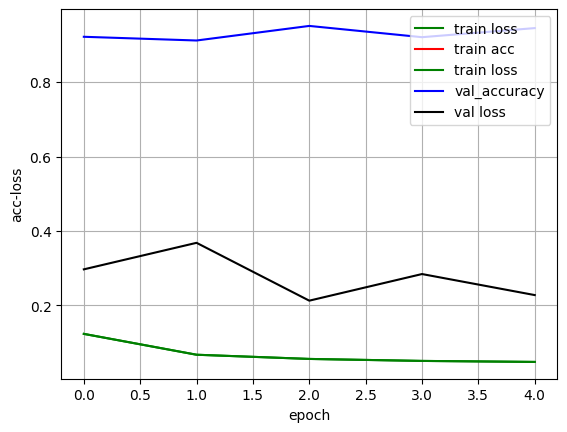

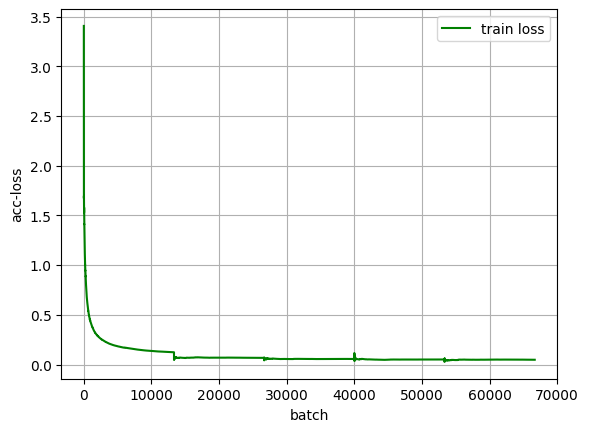

In [12]:
xception(num_class=6,epochs=10)	#binary classificaiton
history_this.loss_plot('epoch')
history_this.loss_plot('batch')
plt.show()

In [8]:
import pandas as pd
import numpy as np
inception = load_model("xception.keras")
y_true = validation_generator.classes  # true labels
y_pred = inception.predict(validation_generator)
y_pred_classes = np.argmax(y_pred, axis=1)
class_names = list(validation_generator.class_indices.keys())
print(classification_report(y_true, y_pred_classes, target_names=class_names))

4419/4419 ━━━━━━━━━━━━━━━━━━━━ 1253s 283ms/step
              precision    recall  f1-score   support

         DoS       0.81      0.99      0.89     75947
       Fuzzy       0.75      0.99      0.85     32063
         RPM       0.03      0.98      0.06       135
    Advanced       0.02      0.98      0.04       400
     Patator       0.24      0.99      0.38      2766
      BENIGN       1.00      0.87      0.93    454264

    accuracy                           0.90    565575
   macro avg       0.47      0.97      0.53    565575
weighted avg       0.96      0.90      0.92    565575



In [9]:
# 1. Get the file paths from the generator
# validation_generator.filenames returns the relative paths (e.g., 'DoS/img_1.png')
file_names = validation_generator.filenames

# 2. Get the actual class names for predictions and true labels
# This converts [0, 1, 2] into ['DoS', 'Fuzzy', 'Patator']
predicted_labels = [class_names[i] for i in y_pred_classes]
true_labels = [class_names[i] for i in y_true]

# 3. Create a DataFrame
results_df = pd.DataFrame({
    'Filename': file_names,
    'True_Label': true_labels,
    'Predicted_Label': predicted_labels
})

# 4. Save to CSV
results_df.to_csv('model_predictions_before_smot.csv', index=False)

print("Predictions saved successfully to 'model_predictions.csv'")

Predictions saved successfully to 'model_predictions.csv'


In [13]:
def efficientnet(num_class, epochs, savepath='./modeels/efficientnet.keras', history=history_this, input_shape=INPUT_SIZE):
    base_model = keras.applications.EfficientNetB3(include_top=False, weights='imagenet', input_shape=input_shape)
    for layer in base_model.layers[:300]:
        layer.trainable = False
    for layer in base_model.layers[300:]:
        layer.trainable = True

    x = GlobalAveragePooling2D()(base_model.output)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.3)(x)
    output = Dense(num_class, activation='softmax')(x)
    model = Model(base_model.input, output, name='efficientnet')

    opt = keras.optimizers.Adam(learning_rate=1e-5)
    model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])

    y_train = train_generator.classes
    class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
    class_weight_dict = dict(enumerate(class_weights))

    callbacks = [
        kcallbacks.EarlyStopping(monitor='val_accuracy', patience=2, mode='max', verbose=1),
        kcallbacks.ModelCheckpoint(filepath=savepath, monitor='val_accuracy', save_best_only=True)
    ]

    model.fit(train_generator,
              validation_data=validation_generator,
              epochs=epochs,
              steps_per_epoch=len(train_generator),
              validation_steps=len(validation_generator),
              callbacks=callbacks + [history],
              class_weight=class_weight_dict)

    y_pred = model.predict(validation_generator)
    y_true = validation_generator.classes
    y_pred_classes = np.argmax(y_pred, axis=1)
    class_names = list(validation_generator.class_indices.keys())
    print(classification_report(y_true, y_pred_classes, target_names=class_names))


13256/13256 ━━━━━━━━━━━━━━━━━━━━ 4231s 316ms/step - accuracy: 0.1982 - loss: 1.8139 - val_accuracy: 0.0567 - val_loss: 2.1953
4419/4419 ━━━━━━━━━━━━━━━━━━━━ 854s 191ms/step
              precision    recall  f1-score   support

         DoS       0.00      0.00      0.00     75947
       Fuzzy       0.06      1.00      0.11     32063
         RPM       0.00      0.00      0.00       135
    Advanced       0.00      0.00      0.00       400
     Patator       0.00      0.00      0.00      2766
      BENIGN       0.00      0.00      0.00    454264

    accuracy                           0.06    565575
   macro avg       0.01      0.17      0.02    565575
weighted avg       0.00      0.06      0.01    565575



/home/minyar/tf-venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/minyar/tf-venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/minyar/tf-venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


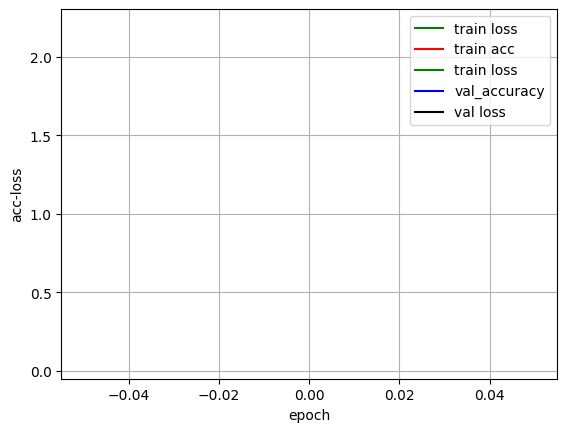

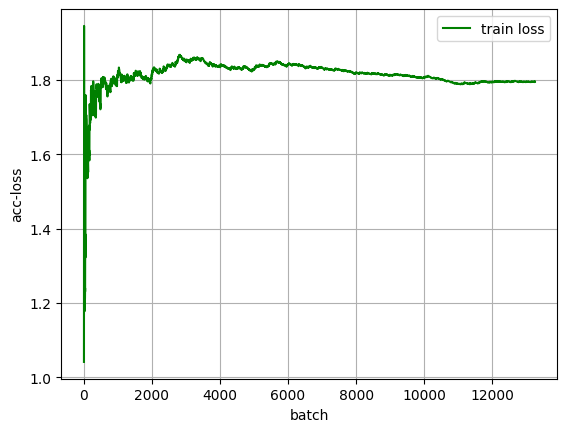

In [14]:
efficientnet(num_class=6,epochs=1)	
history_this.loss_plot('epoch')
history_this.loss_plot('batch')
plt.show()

In [6]:
def zfnet(num_class, epochs, savepath='./zfnet.keras', history=history_this, input_shape=INPUT_SIZE):
    model = keras.Sequential(name='zfnet')
    model.add(Conv2D(16, (7, 7), strides=(2, 2), activation='relu', input_shape=input_shape))
    model.add(MaxPooling2D(pool_size=(3, 3), strides=(2, 2)))
    model.add(Conv2D(128, (5, 5), activation='relu'))
    model.add(MaxPooling2D(pool_size=(3, 3), strides=(2, 2)))
    model.add(Flatten())
    model.add(Dense(64, activation='relu'))
    model.add(Dropout(0.4))
    model.add(Dense(num_class, activation='softmax'))

    opt = keras.optimizers.Adam(learning_rate=1e-3)
    model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])

    y_train = train_generator.classes
    class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
    class_weight_dict = dict(enumerate(class_weights))

    callbacks = [
        kcallbacks.EarlyStopping(monitor='val_accuracy', patience=2, mode='max', verbose=1),
        kcallbacks.ModelCheckpoint(filepath=savepath, monitor='val_accuracy', save_best_only=True)
    ]

    model.fit(train_generator,
              validation_data=validation_generator,
              epochs=epochs,
              steps_per_epoch=len(train_generator),
              validation_steps=len(validation_generator),
              callbacks=callbacks + [history],
              class_weight=class_weight_dict)

    y_pred = model.predict(validation_generator)
    y_true = validation_generator.classes
    y_pred_classes = np.argmax(y_pred, axis=1)
    class_names = list(validation_generator.class_indices.keys())
    print(classification_report(y_true, y_pred_classes, target_names=class_names))


/home/minyar/tf-venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/home/minyar/tf-venv/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
13337/13337 ━━━━━━━━━━━━━━━━━━━━ 2563s 191ms/step - accuracy: 0.8332 - loss: 0.3116 - val_accuracy: 0.9535 - val_loss: 0.1192
Epoch 2/5
13337/13337 ━━━━━━━━━━━━━━━━━━━━ 2616s 196ms/step - accuracy: 0.9379 - loss: 0.0864 - val_accuracy: 0.9437 - val_loss: 0.1334
Epoch 3/5
13337/13337 ━━━━━━━━━━━━━━━━━━━━ 2803s 210ms/step - accuracy: 0.9402 - loss: 0.0740 - val_accuracy: 0.9556 - val_loss: 0.1162
Epoch 4/5
13337/13337 ━━━━━━━━━━━━━━━━━━━━ 2778s 208ms/step - accuracy: 0.9379 - loss: 0.0828 - val_accuracy: 0.9533 - val_loss: 0.1272
Epoch 5/5
13337/13337 ━━━━━━━━━━━━━━━━━━━━ 2740s 205ms/step - accuracy: 0.9397 - loss: 0.0751 - val_accuracy: 0.9457 - val_loss: 0.1711
Epoch 5: early stopping
4419/4419 ━━━━━━━━━━━━━━━━━━━━ 443s 100ms/step
              precision    recall  f1-score   support

         DoS       0.88      0.99      0.93     75947
       Fuzzy       0.82      0.99      0.90     32063
         RPM       0.03      0.90      0.06       135
    Advanced       0.05      0.9

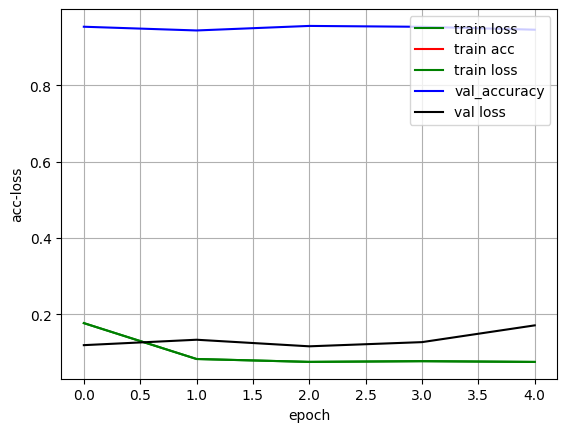

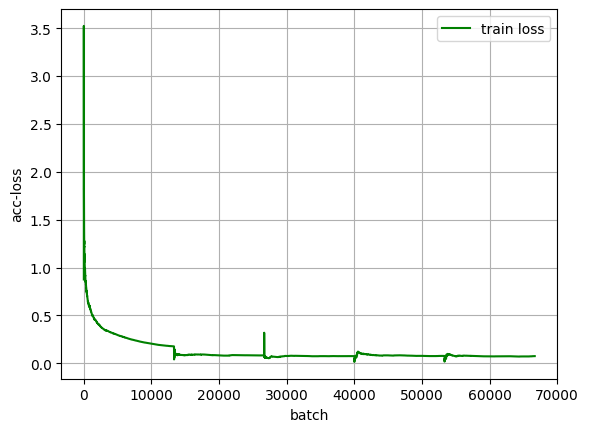

In [7]:
zfnet(num_class=6,epochs=5)	
history_this.loss_plot('epoch')
history_this.loss_plot('batch')
plt.show()

In [19]:
def inception( num_class, epochs,savepath='inception.keras',history=history_this,input_shape=INPUT_SIZE):
    model_fine_tune = InceptionV3(include_top=False, weights='imagenet', input_shape=input_shape)
    for layer in model_fine_tune.layers[:200]:	#the number of frozen layers for transfer learning, have tuned from 50-150
        layer.trainable = False
    for layer in model_fine_tune.layers[200:]:	#the number of trainable layers for transfer learning
        layer.trainable = True
    model = GlobalAveragePooling2D()(model_fine_tune.output)
    model=Dense(units=256,activation='relu')(model)
    model=Dropout(0.5)(model)
    model = Dense(num_class, activation='softmax')(model)
    model = Model(model_fine_tune.input, model, name='resnet')
    opt = keras.optimizers.Adam(learning_rate=0.00001, beta_1=0.9, beta_2=0.999, epsilon=1e-08)	#tuned learning rate to be 0.001
    model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy']) #set the loss function to be binary crossentropy
    #train model
    earlyStopping = kcallbacks.EarlyStopping(
        monitor='val_accuracy', patience=2, verbose=1, mode='max')	#set early stop patience to save training time
    saveBestModel = kcallbacks.ModelCheckpoint(
        filepath=savepath,
        monitor='val_accuracy',
        verbose=1,
        save_best_only=True,
        mode='max')
    hist = model.fit(
        train_generator,
        steps_per_epoch=len(train_generator),
        epochs=epochs,
        validation_data=validation_generator,
        validation_steps=len(validation_generator),
        #use_multiprocessing=True,
        callbacks=[earlyStopping, saveBestModel, history],
    )
    y_true = validation_generator.classes  # true labels
    y_pred = model.predict(validation_generator)
    y_pred_classes = np.argmax(y_pred, axis=1)
    class_names = list(validation_generator.class_indices.keys())
    print(classification_report(y_true, y_pred_classes, target_names=class_names))

13256/13256 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - accuracy: 0.9702 - loss: 0.0816
Epoch 1: val_accuracy improved from -inf to 0.95497, saving model to inception.keras
13256/13256 ━━━━━━━━━━━━━━━━━━━━ 3499s 262ms/step - accuracy: 0.9702 - loss: 0.0816 - val_accuracy: 0.9550 - val_loss: 0.1136
4419/4419 ━━━━━━━━━━━━━━━━━━━━ 651s 146ms/step


/home/minyar/tf-venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/minyar/tf-venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/minyar/tf-venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

         DoS       0.99      0.86      0.92     75947
       Fuzzy       0.80      0.82      0.81     32063
         RPM       0.00      0.00      0.00       135
    Advanced       0.62      0.62      0.62       400
     Patator       1.00      0.50      0.66      2766
      BENIGN       0.96      0.98      0.97    454264

    accuracy                           0.95    565575
   macro avg       0.73      0.63      0.66    565575
weighted avg       0.96      0.95      0.95    565575



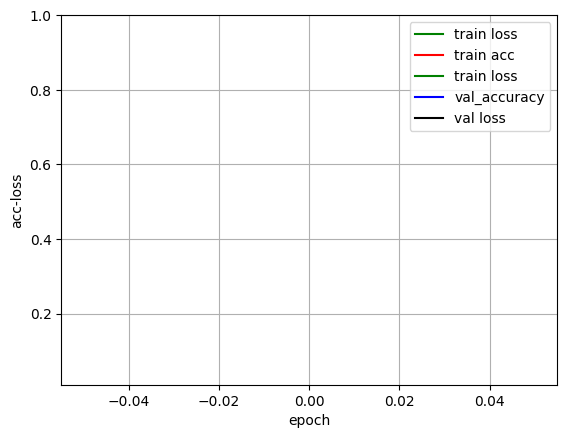

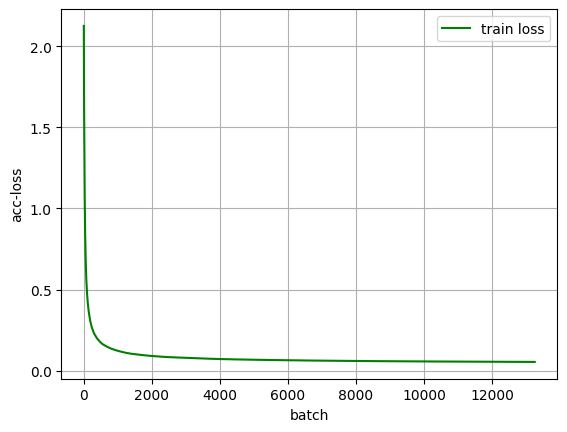

In [20]:
inception(num_class=6,epochs=1)	#binary classificaiton
history_this.loss_plot('epoch')
history_this.loss_plot('batch')
plt.show()

In [16]:
import numpy as np
from tensorflow import keras
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras import callbacks as kcallbacks
from sklearn.metrics import classification_report

# Import the new models
from tensorflow.keras.applications import ResNet50V2, MobileNetV2, DenseNet121

def train_cnn_model(base_model, model_name, num_class, epochs, train_gen, val_gen, history_obj, input_shape=(224,224,3)):
    """
    Dynamically builds, fine-tunes, and trains a given CNN base model.
    """
    # 1. Dynamic Layer Freezing (Freeze the first 75% of the network)
    total_layers = len(base_model.layers)
    freeze_cutoff = int(total_layers * 0.65)
    
    for layer in base_model.layers[:freeze_cutoff]:
        layer.trainable = False
    for layer in base_model.layers[freeze_cutoff:]:
        layer.trainable = True

    # 2. Build the Custom Top Layers
    x = GlobalAveragePooling2D()(base_model.output)
    x = Dense(units=256, activation='relu')(x)
    x = Dropout(0.5)(x)
    predictions = Dense(num_class, activation='softmax')(x)
    
    model = Model(inputs=base_model.input, outputs=predictions, name=model_name)
    
    # 3. Compile Model
    opt = keras.optimizers.Adam(learning_rate=0.001, beta_1=0.8, beta_2=0.999, epsilon=1e-08)
    model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])
    
    # 4. Callbacks
    savepath = f"{model_name}_best.keras"
    earlyStopping = kcallbacks.EarlyStopping(
        monitor='val_accuracy', patience=2, verbose=1, mode='max')
    saveBestModel = kcallbacks.ModelCheckpoint(
        filepath=savepath, monitor='val_accuracy', verbose=1, save_best_only=True, mode='max')
    
    # 5. Train Model
    print(f"--- Starting Training for {model_name} ---")
    hist = model.fit(
        train_gen,
        steps_per_epoch=len(train_gen),
        epochs=epochs,
        validation_data=val_gen,
        validation_steps=len(val_gen),
        callbacks=[earlyStopping, saveBestModel, history_obj]
    )
    
    # 6. Evaluation and Classification Report
    print(f"--- Classification Report for {model_name} ---")
    y_true = val_gen.classes  
    y_pred = model.predict(val_gen)
    y_pred_classes = np.argmax(y_pred, axis=1)
    
    class_names = list(val_gen.class_indices.keys())
    print(classification_report(y_true, y_pred_classes, target_names=class_names))
    
    return model, hist

In [17]:
NUM_CLASSES = 6
EPOCHS = 10
INPUT_SHAPE = (224, 224, 3)

# --- 1. ResNet50V2 ---
resnet_base = ResNet50V2(include_top=False, weights='imagenet', input_shape=INPUT_SHAPE)
resnet_model, resnet_history = train_cnn_model(
    base_model=resnet_base, 
    model_name='ResNet50V2', 
    num_class=NUM_CLASSES, 
    epochs=EPOCHS, 
    train_gen=train_generator, 
    val_gen=validation_generator, 
    history_obj=history_this, # Assuming history_this is a custom callback you defined earlier
    input_shape=INPUT_SHAPE
)

--- Starting Training for ResNet50V2 ---
Epoch 1/10
13337/13337 ━━━━━━━━━━━━━━━━━━━━ 0s 314ms/step - accuracy: 0.9677 - loss: 0.0803
Epoch 1: val_accuracy improved from -inf to 0.97029, saving model to ResNet50V2_best.keras
13337/13337 ━━━━━━━━━━━━━━━━━━━━ 5075s 379ms/step - accuracy: 0.9677 - loss: 0.0803 - val_accuracy: 0.9703 - val_loss: 0.0656
Epoch 2/10
13337/13337 ━━━━━━━━━━━━━━━━━━━━ 0s 313ms/step - accuracy: 0.9815 - loss: 0.0444
Epoch 2: val_accuracy did not improve from 0.97029
13337/13337 ━━━━━━━━━━━━━━━━━━━━ 5008s 375ms/step - accuracy: 0.9815 - loss: 0.0444 - val_accuracy: 0.9559 - val_loss: 0.1306
Epoch 3/10
13334/13337 ━━━━━━━━━━━━━━━━━━━━ 0s 314ms/step - accuracy: 0.9826 - loss: 0.0411
Epoch 3: val_accuracy improved from 0.97029 to 0.97476, saving model to ResNet50V2_best.keras
13337/13337 ━━━━━━━━━━━━━━━━━━━━ 5051s 379ms/step - accuracy: 0.9826 - loss: 0.0411 - val_accuracy: 0.9748 - val_loss: 0.0569
Epoch 4/10
13337/13337 ━━━━━━━━━━━━━━━━━━━━ 0s 315ms/step - accuracy:

In [8]:
# 2. Train Generator (Points directly to the 'train' folder)
train_datagen = ImageDataGenerator(rescale=1./255)
val_test_datagen = ImageDataGenerator(rescale=1./255)
test_test_datagen = ImageDataGenerator(rescale=1./255)
train_generator = train_datagen.flow_from_directory(
    directory='../Images/train/', # Update this to your actual train images path
    classes=wanted_classes, 
    target_size=TARGET_SIZE,
    batch_size=BATCHSIZE,
    class_mode='categorical',
    shuffle=False, # Shuffle training data
    seed=42
)
# 3. Validation Generator (Points directly to the 'val' folder)
validation_generator = val_test_datagen.flow_from_directory(
    directory='../Images/val/', # Update this to your actual val images path
    classes=wanted_classes, 
    target_size=TARGET_SIZE,
    batch_size=BATCHSIZE,
    class_mode='categorical',
    shuffle=False, # Do not shuffle validation data
    seed=42
)

Found 1707118 images belonging to 6 classes.


In [10]:
from tensorflow.keras.models import load_model
TARGET_SIZE = (224, 224)
INPUT_SIZE = (224, 224, 3)
BATCHSIZE = 128
model = load_model("ResNet50V2_best.keras")


# Update these classes based on your actual CICIDS2017 labels
wanted_classes = ['DoS', 'Fuzzy', 'RPM', 'Advanced', 'Patator', 'BENIGN']




import pandas as pd
import numpy as np
import os

def generate_predictions_keras(model, generator, output_csv, prefix="cnn"):

    generator.reset()

    preds = model.predict(generator)

    pred_classes = np.argmax(preds, axis=1)

    confs = np.max(preds, axis=1)

    class_names = list(generator.class_indices.keys())

    rows = []

    for i, filename in enumerate(generator.filenames):

        row = {
            "image_name": os.path.basename(filename),
            "true_label": class_names[generator.classes[i]],
            f"{prefix}_pred": class_names[pred_classes[i]],
            f"{prefix}_confidence": confs[i]
        }

        for c, class_name in enumerate(class_names):
            row[f"{prefix}_{class_name}"] = preds[i][c]

        rows.append(row)

    df = pd.DataFrame(rows)

    df.to_csv(output_csv, index=False)

    print(f"Saved: {output_csv}")

    
# Train
generate_predictions_keras(
model, train_generator, "resnet_train_predictions_new.csv"
)

# Validation
generate_predictions_keras(
   model, validation_generator, "resnet_val_predictions_new.csv"
)

# Test
#generate_predictions_keras(
#    model, test_generator, "test_predictions.csv"
#)


2026-06-01 01:09:36.156752: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1503', 3420 bytes spill stores, 3344 bytes spill loads



13336/13337 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step

2026-06-01 01:55:31.465674: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1510', 4 bytes spill stores, 4 bytes spill loads

2026-06-01 01:55:32.326259: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1503', 10232 bytes spill stores, 10436 bytes spill loads



13337/13337 ━━━━━━━━━━━━━━━━━━━━ 2776s 206ms/step
Saved: resnet_train_predictions_new.csv
4418/4419 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step

2026-06-01 02:11:27.194456: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1503', 10232 bytes spill stores, 10436 bytes spill loads



4419/4419 ━━━━━━━━━━━━━━━━━━━━ 922s 209ms/step
Saved: resnet_val_predictions_new.csv


In [21]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

def plot_confusion_matrix(y_true, y_pred, class_names, title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.figure(figsize=(8,6))
    plt.imshow(cm_norm)
    plt.title(title)
    plt.colorbar()

    ticks = np.arange(len(class_names))
    plt.xticks(ticks, class_names, rotation=45)
    plt.yticks(ticks, class_names)

    for i in range(len(class_names)):
        for j in range(len(class_names)):
            plt.text(j, i, f"{cm_norm[i,j]:.2f}", ha='center', va='center')

    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.show()

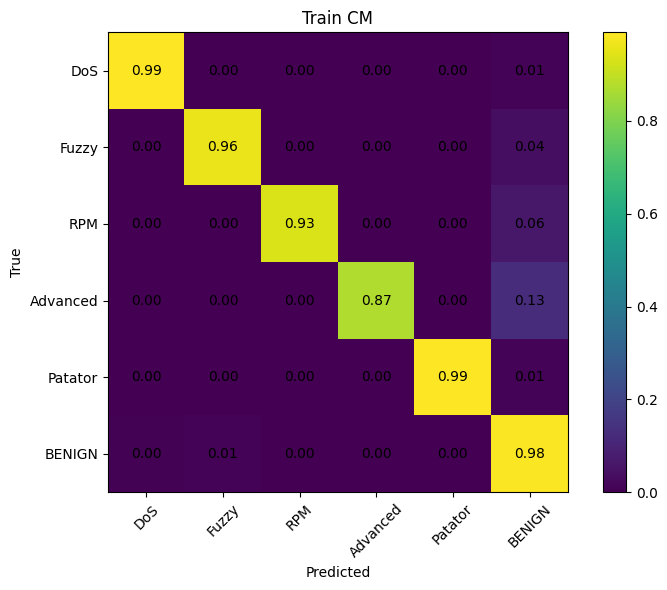

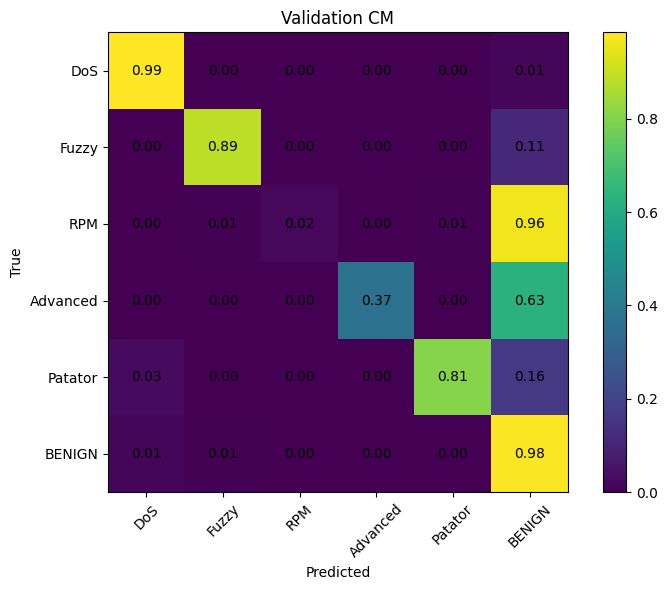

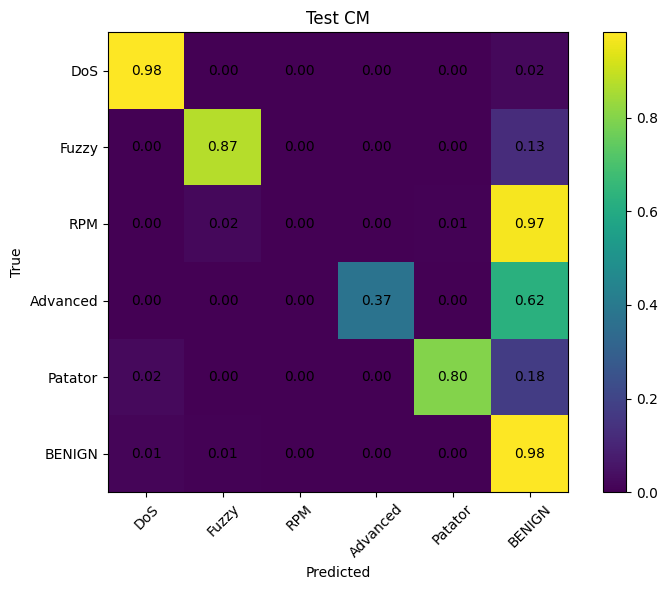

In [22]:
plot_confusion_matrix(y_train, y_train_pred, class_names, "Train CM")
plot_confusion_matrix(y_val, y_val_pred, class_names, "Validation CM")
plot_confusion_matrix(y_test, y_test_pred, class_names, "Test CM")

In [23]:
# --- 2. MobileNetV2 ---
mobilenet_base = MobileNetV2(include_top=False, weights='imagenet', input_shape=INPUT_SHAPE)
mobilenet_model, mobilenet_history = train_cnn_model(
    base_model=mobilenet_base, 
    model_name='MobileNetV2', 
    num_class=NUM_CLASSES, 
    epochs=EPOCHS, 
    train_gen=train_generator, 
    val_gen=validation_generator, 
    history_obj=history_this,
    input_shape=INPUT_SHAPE
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 14s 1us/step
--- Starting Training for MobileNetV2 ---


2026-04-29 22:32:06.897080: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3507', 4 bytes spill stores, 4 bytes spill loads

2026-04-29 22:32:07.645462: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3175', 1224 bytes spill stores, 1176 bytes spill loads



   34/13256 ━━━━━━━━━━━━━━━━━━━━ 51:11 232ms/step - accuracy: 0.4960 - loss: 1.3725

2026-04-29 22:32:32.836444: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3507', 4 bytes spill stores, 4 bytes spill loads

2026-04-29 22:32:33.188534: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3509', 148 bytes spill stores, 148 bytes spill loads

2026-04-29 22:32:33.501601: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3175', 1616 bytes spill stores, 1232 bytes spill loads



13256/13256 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.9589 - loss: 0.1086

2026-04-29 23:16:17.748990: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1207', 1616 bytes spill stores, 1232 bytes spill loads




Epoch 1: val_accuracy improved from -inf to 0.95278, saving model to MobileNetV2_best.keras
13256/13256 ━━━━━━━━━━━━━━━━━━━━ 2668s 199ms/step - accuracy: 0.9589 - loss: 0.1086 - val_accuracy: 0.9528 - val_loss: 0.1087
--- Classification Report for MobileNetV2 ---
4419/4419 ━━━━━━━━━━━━━━━━━━━━ 797s 179ms/step
              precision    recall  f1-score   support

         DoS       0.81      1.00      0.89     75947
       Fuzzy       0.91      0.83      0.87     32063
         RPM       0.00      0.00      0.00       135
    Advanced       0.00      0.00      0.00       400
     Patator       1.00      0.67      0.80      2766
      BENIGN       0.99      0.96      0.97    454264

    accuracy                           0.95    565575
   macro avg       0.62      0.58      0.59    565575
weighted avg       0.96      0.95      0.95    565575



/home/minyar/tf-venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/minyar/tf-venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/minyar/tf-venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# --- 3. DenseNet121 ---
densenet_base = DenseNet121(include_top=False, weights='imagenet', input_shape=INPUT_SHAPE)
densenet_model, densenet_history = train_cnn_model(
    base_model=densenet_base, 
    model_name='DenseNet121', 
    num_class=NUM_CLASSES, 
    epochs=EPOCHS, 
    train_gen=train_generator, 
    val_gen=validation_generator, 
    history_obj=history_this,
    input_shape=INPUT_SHAPE
)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 53s 2us/step
--- Starting Training for DenseNet121 ---


2026-04-29 23:31:15.161235: W tensorflow/core/kernels/data/prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 77073408 bytes after encountering the first element of size 77073408 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size
2026-04-29 23:31:19.552561: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_18610', 4 bytes spill stores, 4 bytes spill loads

2026-04-29 23:31:20.150330: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_15967', 640 bytes spill stores, 640 bytes spill loads



 2069/13256 ━━━━━━━━━━━━━━━━━━━━ 40:18 216ms/step - accuracy: 0.9113 - loss: 0.2670

2026-04-29 23:39:36.223927: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_18610', 4 bytes spill stores, 4 bytes spill loads

2026-04-29 23:39:36.537731: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_24732', 148 bytes spill stores, 148 bytes spill loads

2026-04-29 23:39:37.081453: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_15967', 9848 bytes spill stores, 10720 bytes spill loads



13254/13256 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step - accuracy: 0.9565 - loss: 0.1176

2026-04-30 00:35:21.394020: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3346', 9848 bytes spill stores, 10720 bytes spill loads



In [15]:
class_names = list(validation_generator.class_indices.keys())
print(classification_report(y_true, y_pred_classes, target_names=class_names))

              precision    recall  f1-score   support

         DoS       1.00      0.81      0.89     75947
       Fuzzy       0.99      0.50      0.66     32063
         RPM       0.00      0.00      0.00       135
    Advanced       0.98      0.34      0.50       400
     Patator       1.00      0.50      0.66      2766
      BENIGN       0.93      1.00      0.97    454264

    accuracy                           0.94    565575
   macro avg       0.82      0.52      0.61    565575
weighted avg       0.94      0.94      0.94    565575



/home/minyar/tf-venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/minyar/tf-venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/minyar/tf-venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [26]:
import numpy as np
import pandas as pd
from tensorflow.keras.models import load_model

# -----------------------
# Config
# -----------------------
model_paths = {
    "Inception": "inception.keras",
    "Xception": "xception.keras",
    "Zfnet": "zfnet.keras",
    "efficientnet": "efficientnet.keras"
}

output_csv = "cnn_predictions.csv"

# -----------------------
# Assuming you already have a validation_generator
# validation_generator should be a Keras ImageDataGenerator.flow_from_directory
# -----------------------
# Get true labels
y_true = validation_generator.classes
filenames = validation_generator.filenames
class_names = list(validation_generator.class_indices.keys())  # e.g., ['BENIGN', 'THREAT']

# Create dataframe
df = pd.DataFrame({"Filename": filenames})
df["TrueLabel"] = [class_names[i] for i in y_true]

# -----------------------
# Loop over models
# -----------------------
for model_name, model_path in model_paths.items():
    print(f"Loading {model_name} from {model_path}...")
    model = load_model(model_path)

    print(f"Predicting with {model_name}...")
    y_pred_prob = model.predict(validation_generator, verbose=1)  # shape [num_samples, num_classes]
    y_pred_classes = np.argmax(y_pred_prob, axis=1)
    y_pred_labels = [class_names[i] for i in y_pred_classes]

    # Add to dataframe
    df[f"{model_name}_PredLabel"] = y_pred_labels

# -----------------------
# Save to CSV
# -----------------------
df.to_csv(output_csv, index=False)
print(f"✅ Predictions saved to {output_csv}")


Loading Inception from inception.keras...
Predicting with Inception...
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 876s 651ms/step
Loading Xception from xception.keras...
Predicting with Xception...


2025-11-03 18:26:07.347467: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng0{} for conv %cudnn-conv.75 = (f32[128,64,109,109]{3,2,1,0}, u8[0]{0}) custom-call(f32[128,32,111,111]{3,2,1,0} %bitcast.4244, f32[64,32,3,3]{3,2,1,0} %bitcast.4251), window={size=3x3}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convForward", metadata={op_type="Conv2D" op_name="xception_1/block1_conv2_1/convolution" source_file="/home/minyar/tf-venv/lib/python3.12/site-packages/tensorflow/python/framework/ops.py" source_line=1200}, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"conv_result_scale":1,"activation_mode":"kNone","side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false} is taking a while...
2025-11-03 18:26:07.642156: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.276635124s
Trying algorithm eng0{} for conv %cudnn-conv.75 = (f32[128,64,109,109]{3,2,1

1312/1313 ━━━━━━━━━━━━━━━━━━━━ 0s 662ms/step

2025-11-03 18:42:10.459015: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng34{k2=0,k4=1,k5=1,k6=0,k7=0,k19=0} for conv %cudnn-conv.78 = (f32[73,128,109,109]{3,2,1,0}, u8[0]{0}) custom-call(f32[73,128,109,109]{3,2,1,0} %bitcast.4336, f32[128,1,3,3]{3,2,1,0} %bitcast.4343), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, feature_group_count=128, custom_call_target="__cudnn$convForward", metadata={op_type="DepthwiseConv2dNative" op_name="xception_1/block2_sepconv2_1/separable_conv2d/depthwise" source_file="/home/minyar/tf-venv/lib/python3.12/site-packages/tensorflow/python/framework/ops.py" source_line=1200}, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"conv_result_scale":1,"activation_mode":"kNone","side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false} is taking a while...
2025-11-03 18:42:10.761467: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The ope

1313/1313 ━━━━━━━━━━━━━━━━━━━━ 1007s 699ms/step
Loading Zfnet from zfnet.keras...
Predicting with Zfnet...


2025-11-03 18:42:50.805477: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng0{} for conv %cudnn-conv-bias-activation.7 = (f32[128,128,50,50]{3,2,1,0}, u8[0]{0}) custom-call(f32[128,16,54,54]{3,2,1,0} %bitcast.199, f32[128,16,5,5]{3,2,1,0} %bitcast.206, f32[128]{0} %bitcast.208), window={size=5x5}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", metadata={op_type="Conv2D" op_name="zfnet_1/conv2d_5_1/convolution" source_file="/home/minyar/tf-venv/lib/python3.12/site-packages/tensorflow/python/framework/ops.py" source_line=1200}, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"conv_result_scale":1,"activation_mode":"kRelu","side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false} is taking a while...
2025-11-03 18:42:51.321679: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.51661645s
Trying algorithm eng0{} for conv 

1313/1313 ━━━━━━━━━━━━━━━━━━━━ 372s 278ms/step
Loading efficientnet from efficientnet.keras...
Predicting with efficientnet...


2025-11-03 18:49:19.003829: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3225', 560 bytes spill stores, 560 bytes spill loads

2025-11-03 18:49:19.074690: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3225', 468 bytes spill stores, 468 bytes spill loads

2025-11-03 18:49:19.097626: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3225', 120 bytes spill stores, 120 bytes spill loads

2025-11-03 18:49:19.155359: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3225_0', 120 bytes spill stores, 120 bytes spill loads

2025-11-03 18:49:19.311512: I 

1312/1313 ━━━━━━━━━━━━━━━━━━━━ 0s 395ms/step

2025-11-03 18:59:06.411490: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3225', 16 bytes spill stores, 16 bytes spill loads

2025-11-03 18:59:06.650498: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3225_0', 108 bytes spill stores, 108 bytes spill loads

2025-11-03 18:59:06.698870: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3225', 236 bytes spill stores, 280 bytes spill loads

2025-11-03 18:59:06.823378: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3225', 476 bytes spill stores, 476 bytes spill loads

2025-11-03 18:59:06.923977: I ex

1313/1313 ━━━━━━━━━━━━━━━━━━━━ 640s 434ms/step
✅ Predictions saved to cnn_predictions.csv
